In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import clear_output

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import r2_score, mean_squared_error

import os

In [2]:
FOAM_RUN = os.environ.get('FOAM_RUN')
df = pd.read_csv(f'{FOAM_RUN}/cavity_data.csv')

X = df[['x','y','Re']].values
y = df[['Ux','Uy']].values

############ Split the data into training and test sets ############################
mask = df['Re']==700

X_train = X[~mask]
y_train = y[~mask]

X_test = X[mask]
y_test = y[mask]

############        Normalize the data                  ############################

def min_max_func(train_data):
    train_data_min = np.min(train_data, axis=0)
    train_data_max = np.max(train_data, axis=0)
    return train_data_min, train_data_max

def scale_data(data, data_min, data_max):
    return (data - data_min) / (data_max - data_min)

X_train_min, X_train_max = min_max_func(X_train)
X_train_scaled = scale_data(X_train, X_train_min, X_train_max)

X_test_scaled = scale_data(X_test, X_train_min, X_train_max)

############         Convert to PyTorch tensors         ############################

X_train_t = torch.tensor(X_train_scaled,dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled,dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

print(X_train_t.shape, y_train_t.shape, X_test_t.shape, y_test_t.shape)
print(X_train_t.dtype, y_train_t.dtype, X_test_t.dtype, y_test_t.dtype)

dataset = TensorDataset(X_train_t, y_train_t)
loader = DataLoader(dataset, batch_size = 256, shuffle = True)


torch.Size([25600, 3]) torch.Size([25600, 2]) torch.Size([6400, 3]) torch.Size([6400, 2])
torch.float32 torch.float32 torch.float32 torch.float32


In [3]:
#=============================MODEL DEFINITION=====================================#
############             Multilayer Perceptron           ############################

torch.manual_seed(42)
model = nn.Sequential(
    nn.Linear(3,64),
    nn.Tanh(),
    nn.Linear(64,64),
    nn.Tanh(),
    nn.Linear(64,64),
    nn.Tanh(),
    nn.Linear(64,2)
)
print(model)
print(model[0].weight[0], model[0].bias[0])


############         counting the parameters             ############################

print(sum(p.numel() for p in model.parameters()))

for p in model.parameters():
    print(p.shape, p.numel())


Sequential(
  (0): Linear(in_features=3, out_features=64, bias=True)
  (1): Tanh()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): Tanh()
  (4): Linear(in_features=64, out_features=64, bias=True)
  (5): Tanh()
  (6): Linear(in_features=64, out_features=2, bias=True)
)
tensor([ 0.4414,  0.4792, -0.1353], grad_fn=<SelectBackward0>) tensor(0.3690, grad_fn=<SelectBackward0>)
8706
torch.Size([64, 3]) 192
torch.Size([64]) 64
torch.Size([64, 64]) 4096
torch.Size([64]) 64
torch.Size([64, 64]) 4096
torch.Size([64]) 64
torch.Size([2, 64]) 128
torch.Size([2]) 2


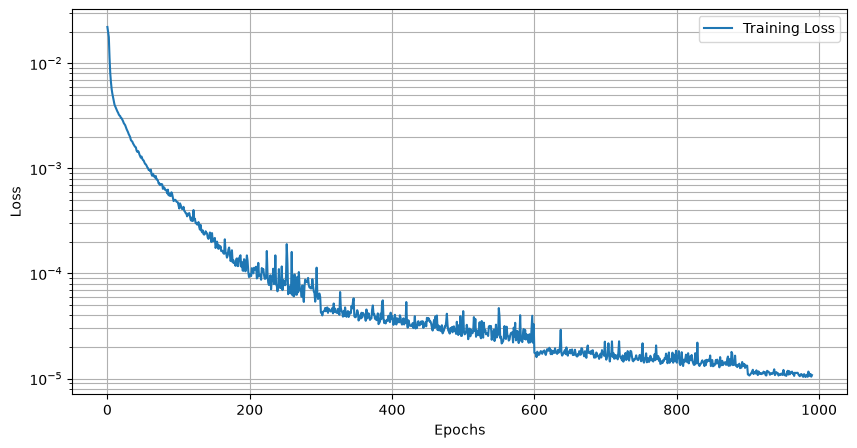

epoch 0: loss = 0.022134, lr = 0.001000
epoch 100: loss = 0.000445, lr = 0.001000
epoch 200: loss = 0.000099, lr = 0.001000
epoch 300: loss = 0.000042, lr = 0.000500
epoch 400: loss = 0.000040, lr = 0.000500
epoch 500: loss = 0.000044, lr = 0.000500
epoch 600: loss = 0.000018, lr = 0.000250
epoch 700: loss = 0.000017, lr = 0.000250
epoch 800: loss = 0.000014, lr = 0.000250
epoch 900: loss = 0.000011, lr = 0.000125


In [5]:
#===============================  TRAINING  =======================================#

optimizer = torch.optim.Adam(model.parameters(), lr = 1e-3)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=300, gamma=0.5)
loss_fn = nn.MSELoss()

losses = []
log = []
for epoch in range(1000):
    epoch_loss = 0
    for X_batch, y_batch in loader:
        optimizer.zero_grad()
        model_out = model(X_batch)
        loss = loss_fn(model_out,y_batch)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    avg_loss = epoch_loss/ len(loader)
    losses.append(avg_loss)
    scheduler.step()

    if epoch % 100 == 0:
        lr = optimizer.param_groups[0]['lr']
        log.append(f"epoch {epoch}: loss = {avg_loss:.6f}, lr = {lr:.6f}")

    if epoch % 10 == 0:                                         # redraw the loss curve every 10 epochs
        clear_output(wait=True)
        plt.figure(figsize=(10, 5))
        plt.semilogy(losses,label='Training Loss')
        plt.xlabel('Epochs')
        plt.ylabel('Loss')
        plt.grid(True,which='both',ls='-')
        plt.legend()
        plt.show()
        for line in log:
            print(line)


In [6]:
#===============           PREDICTION              ================================#
############          Predict on the test data          ############################
with torch.no_grad():
    y_pred = model(X_test_t).numpy()

In [11]:
#===============           EVALUATION              ================================#
############                  Metrics                   ############################

for i, name in enumerate(['Ux','Uy']):
    r2 = r2_score(y_test[:, i], y_pred[:, i])
    rmse = np.sqrt(mean_squared_error(y_test[:, i], y_pred[:, i]))
    max_err = np.max(np.abs(y_test[:, i] - y_pred[:, i]))
    print(f"{name}: R2 = {r2:.4f}, RMSE = {rmse:.4f}, max |error| = {max_err:.4f}")
    
err = np.abs(y_test[:,1] - y_pred[:,1])
ind = np.argmax(err)
print(X_test[ind],y_test[ind],y_pred[ind])


Ux: R2 = 0.9995, RMSE = 0.0047, max |error| = 0.0550
Uy: R2 = 0.9995, RMSE = 0.0045, max |error| = 0.0498
[  0.99375   0.98125 700.     ] [ 0.0978303 -0.39741  ] [ 0.08491078 -0.34765893]


In [12]:
cell = df[np.isclose(df['x'],0.99375) & np.isclose(df['y'],0.93125)]
X_cell = cell[['x', 'y', 'Re']].values
X_cell_t = torch.tensor(scale_data(X_cell, X_train_min, X_train_max), dtype=torch.float32)

with torch.no_grad():
    Uy_pred = model(X_cell_t).numpy()[:,1]

cell = cell.assign(Uy_pred=Uy_pred)
print(cell[['Re','Uy','Uy_pred']])


         Re        Uy   Uy_pred
5999    100 -0.180936 -0.191934
12399   400 -0.301266 -0.330025
18799  1000 -0.451642 -0.464878
25199  2000 -0.566846 -0.570114
31599   700 -0.385815 -0.415667


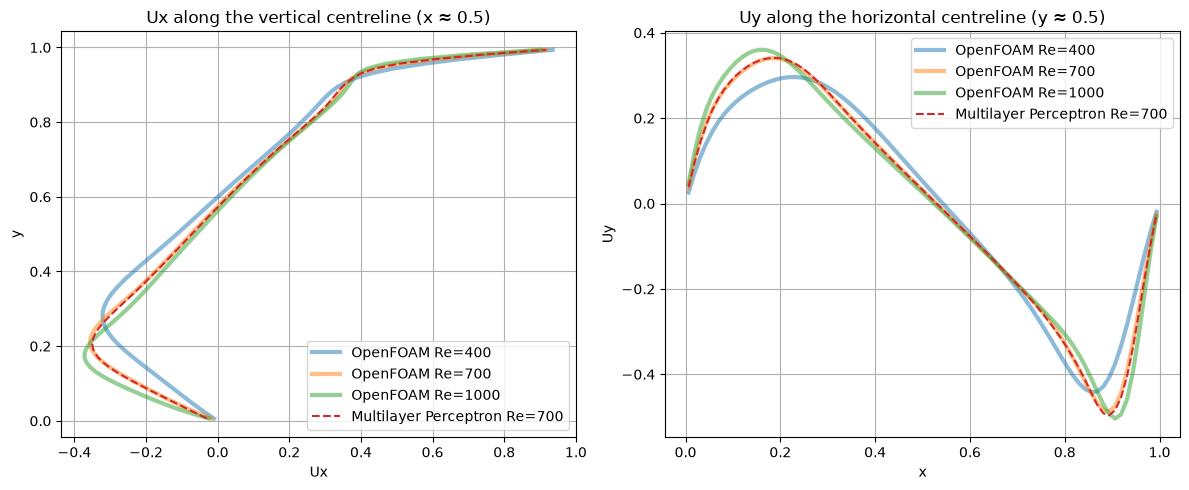

In [18]:
#===============          Centerline plot          ================================#

# Cell-centre (x, y) coordinates: identical for every Re
coords = X_test[:, :2]

def vertical_centreline(field,coords):
    #cells on the vertical line closest to x = 0.5. Returns y and velocities
    x_c = coords[:,0]
    y_c = coords[:,1]

    #find the x value closest to 0.5 
    x_line = x_c[np.argmin(np.abs(x_c - 0.5))]

    #select the 80 cells at this x
    sel = np.isclose(x_c,x_line)

    #sort from bottom to top
    order = np.argsort(y_c[sel])
    return y_c[sel][order],field[sel][order]

def horizontal_centreline(field, coords):
    """Cells on the horizontal line closest to y = 0.5. Returns x and velocities."""
    x_c = coords[:, 0]
    y_c = coords[:, 1]
 
    # 1. Find the y value closest to 0.5
    y_line = y_c[np.argmin(np.abs(y_c - 0.5))]
 
    # 2. Select the 80 cells at this y
    sel = np.isclose(y_c, y_line)
 
    # 3. Sort from left to right
    order = np.argsort(x_c[sel])
    return x_c[sel][order], field[sel][order]



fields = {
    'OpenFOAM Re=400': y[(df['Re'] == 400).values],
    'OpenFOAM Re=700': y_test,
    'OpenFOAM Re=1000': y[(df['Re'] == 1000).values],
    'Multilayer Perceptron Re=700': y_pred,
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
 
for label, field in fields.items():
    if not label.startswith('OpenFOAM'):
        style = dict(linestyle='--', linewidth=1.5)
    else:
        # Thick, semi-transparent CFD curves so the model curves on top stay visible
        style = dict(linestyle='-', linewidth=3, alpha=0.5)
 
    y_line, U = vertical_centreline(field, coords)
    axes[0].plot(U[:, 0], y_line, label=label, **style)
 
    x_line, U = horizontal_centreline(field, coords)
    axes[1].plot(x_line, U[:, 1], label=label, **style)
 
axes[0].set_xlabel('Ux')
axes[0].set_ylabel('y')
axes[0].set_title('Ux along the vertical centreline (x ≈ 0.5)')
 
axes[1].set_xlabel('x')
axes[1].set_ylabel('Uy')
axes[1].set_title('Uy along the horizontal centreline (y ≈ 0.5)')
 
for ax in axes:
    ax.grid(True)
    ax.legend()
 
plt.tight_layout()
plt.savefig("NN_centerline_Re700.png", dpi=150)
plt.show()

In [36]:
#===============   Comparison with the average of CFD(400) and CFD(1000)   ================================#


cfd_400 = y[(df['Re'] == 400).values]
cfd_1000 = y[(df['Re'] == 1000).values]
cfd_avg = (cfd_400 + cfd_1000) / 2

#average to pred
print(f" average to pred")
for i, name in enumerate(['Ux','Uy']):
    r2 = r2_score(cfd_avg[:, i], y_pred[:, i])
    rmse = np.sqrt(mean_squared_error(cfd_avg[:, i], y_pred[:, i]))
    max_err = np.max(np.abs(cfd_avg[:, i] - y_pred[:, i]))
    print(f"{name}: R2 = {r2:.4f}, RMSE = {rmse:.4f}, max |error| = {max_err:.4f}")
    
#average to test
print(f" average to test")
for i, name in enumerate(['Ux','Uy']):
    r2 = r2_score(y_test[:, i], cfd_avg[:, i])
    rmse = np.sqrt(mean_squared_error(y_test[:, i], cfd_avg[:, i]))
    max_err = np.max(np.abs(y_test[:, i] - cfd_avg[:, i]))
    print(f"{name}: R2 = {r2:.4f}, RMSE = {rmse:.4f}, max |error| = {max_err:.4f}")





 average to pred
Ux: R2 = 0.9965, RMSE = 0.0124, max |error| = 0.0503
Uy: R2 = 0.9961, RMSE = 0.0119, max |error| = 0.0482
 average to test
Ux: R2 = 0.9971, RMSE = 0.0115, max |error| = 0.0393
Uy: R2 = 0.9976, RMSE = 0.0095, max |error| = 0.0380


In [48]:
#===============        PREDICTION  for Re = 1500      ================================#
X_1500 = X_test.copy()
X_1500[:,2] = 1500

X_1500_scaled = scale_data(X_1500, X_train_min, X_train_max)

X_1500_t = torch.tensor(X_1500_scaled,dtype=torch.float32)


with torch.no_grad():
    y_pred_1500 = model(X_1500_t).numpy()

In [ ]:
############                  Re 1500 CFD data          ############################
df_1500 = pd.read_csv(f"{FOAM_RUN}/cavity_data_1500.csv")
y_1500 = df_1500[['Ux', 'Uy']].values
assert np.allclose(df_1500[['x', 'y']].values, X_test[:, :2])   # same row order as the Re = 700 test data

#===============           EVALUATION              ================================#
############                  Metrics                   ############################

for i, name in enumerate(['Ux','Uy']):
    r2 = r2_score(y_1500[:, i], y_pred_1500[:, i])
    rmse = np.sqrt(mean_squared_error(y_1500[:, i], y_pred_1500[:, i]))
    max_err = np.max(np.abs(y_1500[:, i] - y_pred_1500[:, i]))
    print(f"{name}: R2 = {r2:.4f}, RMSE = {rmse:.4f}, max |error| = {max_err:.4f}")


cfd_2000 = y[(df['Re'] == 2000).values]
cfd_avg_1500 = (cfd_1000 + cfd_2000) / 2

#average to pred
print(f" average to pred")
for i, name in enumerate(['Ux','Uy']):
    r2 = r2_score(cfd_avg_1500[:, i], y_pred_1500[:, i])
    rmse = np.sqrt(mean_squared_error(cfd_avg_1500[:, i], y_pred_1500[:, i]))
    max_err = np.max(np.abs(cfd_avg_1500[:, i] - y_pred_1500[:, i]))
    print(f"{name}: R2 = {r2:.4f}, RMSE = {rmse:.4f}, max |error| = {max_err:.4f}")
    
#average to test
print(f" average to test")
for i, name in enumerate(['Ux','Uy']):
    r2 = r2_score(y_1500[:, i], cfd_avg_1500[:, i])
    rmse = np.sqrt(mean_squared_error(y_1500[:, i], cfd_avg_1500[:, i]))
    max_err = np.max(np.abs(y_1500[:, i] - cfd_avg_1500[:, i]))
    print(f"{name}: R2 = {r2:.4f}, RMSE = {rmse:.4f}, max |error| = {max_err:.4f}")

Ux: R2 = 0.9991, RMSE = 0.0062, max |error| = 0.0677
Uy: R2 = 0.9995, RMSE = 0.0045, max |error| = 0.0425
 average to pred
Ux: R2 = 0.9984, RMSE = 0.0082, max |error| = 0.0749
Uy: R2 = 0.9993, RMSE = 0.0052, max |error| = 0.0452
 average to test
Ux: R2 = 0.9992, RMSE = 0.0058, max |error| = 0.0214
Uy: R2 = 0.9993, RMSE = 0.0053, max |error| = 0.0230


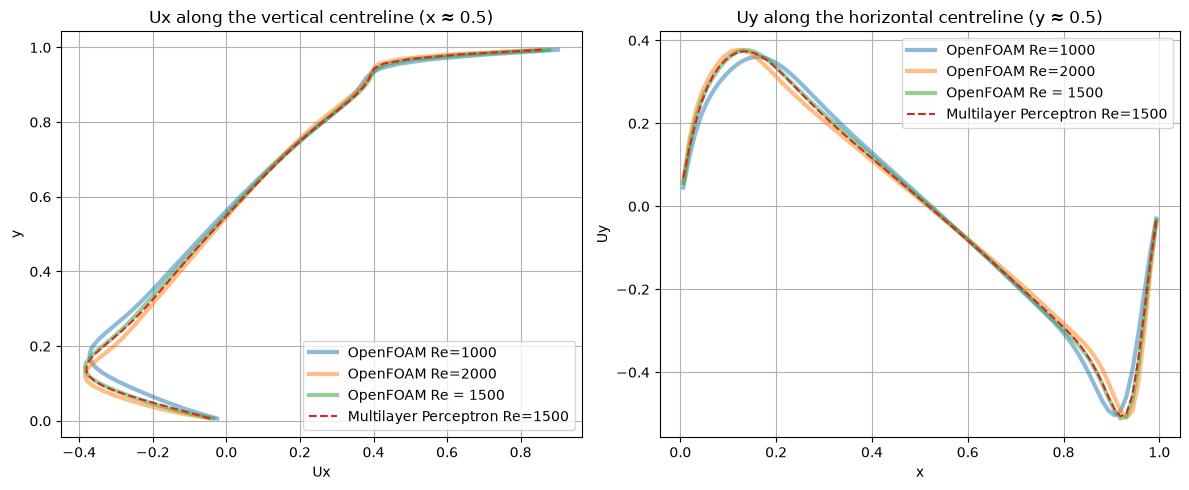

In [57]:

fields = {
    'OpenFOAM Re=1000': y[(df['Re'] == 1000).values],
    'OpenFOAM Re=2000': y[(df['Re'] == 2000).values],
    'OpenFOAM Re = 1500': y_1500,
    'Multilayer Perceptron Re=1500': y_pred_1500,
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
 
for label, field in fields.items():
    if not label.startswith('OpenFOAM'):
        style = dict(linestyle='--', linewidth=1.5)
    else:
        # Thick, semi-transparent CFD curves so the model curves on top stay visible
        style = dict(linestyle='-', linewidth=3, alpha=0.5)
 
    y_line, U = vertical_centreline(field, coords)
    axes[0].plot(U[:, 0], y_line, label=label, **style)
 
    x_line, U = horizontal_centreline(field, coords)
    axes[1].plot(x_line, U[:, 1], label=label, **style)
 
axes[0].set_xlabel('Ux')
axes[0].set_ylabel('y')
axes[0].set_title('Ux along the vertical centreline (x ≈ 0.5)')
 
axes[1].set_xlabel('x')
axes[1].set_ylabel('Uy')
axes[1].set_title('Uy along the horizontal centreline (y ≈ 0.5)')
 
for ax in axes:
    ax.grid(True)
    ax.legend()
 
plt.tight_layout()
plt.savefig("NN_centerline_Re1500.png", dpi=150)
plt.show()

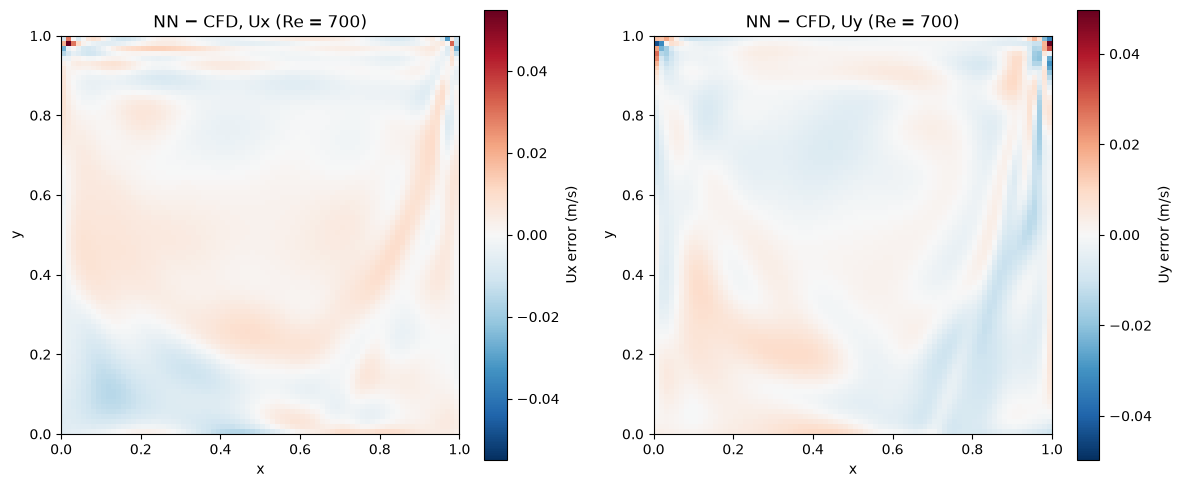

In [58]:
#===============          Difference plots          ================================#

diff = y_pred - y_test          # NN − CFD, shape (6400, 2)

coords_1d = np.linspace(1/160, 1 - 1/160, 80)   # cell centres, same as in the extraction script

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, name in enumerate(['Ux', 'Uy']):
    field = diff[:, i].reshape(80, 80)          # rows = y, columns = x
    m = np.max(np.abs(field))                   # symmetric colour scale centred at zero

    pc = axes[i].pcolormesh(coords_1d, coords_1d, field,
                            cmap='RdBu_r', vmin=-m, vmax=m, shading='auto')
    fig.colorbar(pc, ax=axes[i], label=f'{name} error (m/s)')

    axes[i].set_title(f'NN − CFD, {name} (Re = 700)')
    axes[i].set_xlabel('x')
    axes[i].set_ylabel('y')
    axes[i].set_aspect('equal')

plt.tight_layout()
plt.savefig("NN_difference_Re700.png", dpi=150)
plt.show()

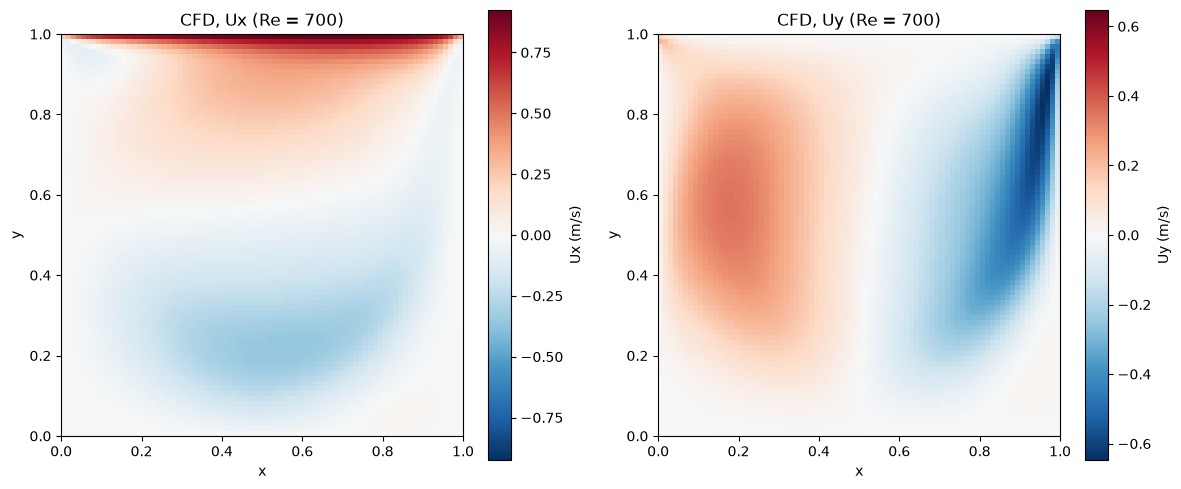

In [59]:
#===============          CFD fields, Re = 700          ================================#

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, name in enumerate(['Ux', 'Uy']):
    field = y_test[:, i].reshape(80, 80)
    m = np.max(np.abs(field))                   # centred at zero, so the flow direction shows as colour

    pc = axes[i].pcolormesh(coords_1d, coords_1d, field,
                            cmap='RdBu_r', vmin=-m, vmax=m, shading='auto')
    fig.colorbar(pc, ax=axes[i], label=f'{name} (m/s)')

    axes[i].set_title(f'CFD, {name} (Re = 700)')
    axes[i].set_xlabel('x')
    axes[i].set_ylabel('y')
    axes[i].set_aspect('equal')

plt.tight_layout()
plt.savefig("CFD_fields_Re700.png", dpi=150)
plt.show()